# Chapitre 9 - Exercices 9.7 à 9.12

Ce notebook traite six exercices sur le décodage, l'attention et le service :

- **9.7** : accélération du décodage spéculatif, de la formule à la mesure ;
- **9.8** : cache KV de Llama 3-70B et nombre d'utilisateurs simultanés ;
- **9.9** : PagedAttention, choisir la taille des blocs ;
- **9.10** : batching dynamique, régler la fenêtre ;
- **9.11** : rentabilité du cache de prompt (stockage, durée de vie) et mesure du TTFT ;
- **9.12** : répartir Llama 3-70B sur 8 GPU (tenseur, pipeline, répliques).

In [1]:
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from aie import llm
from aie import ch09_inference as inf
from aie.ch02_modeles import KNOWN_CONFIGS, count_params_config, kv_cache_bytes, plain_log_axis
from aie.diagrams import Diagram
from aie.plotting import (set_style, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, LIGHT, COLORS,
                          annotate_bars, subtitle, finish)

set_style()
warnings.filterwarnings("ignore")
llm.seed_everything(0)
rng = np.random.default_rng(0)
pd.set_option("display.precision", 3)
H100 = inf.ACCELERATORS["H100 SXM"]
GB = 1e9

## Exercice 9.7 : Accélération du décodage spéculatif

**Énoncé.**

1. On suppose que chaque token proposé est accepté avec probabilité $\alpha$,
   indépendamment, tant que les précédents l'ont été. Montrer que le nombre $J$ de tokens
   acceptés sur $k$ proposés suit $P(J = j) = \alpha^j(1 - \alpha)$ pour $j < k$ et
   $P(J = k) = \alpha^k$, puis que $\mathbb{E}[1 + J] = \frac{1 - \alpha^{k+1}}{1 - \alpha}$.
2. Exemple du livre (Chen et al., 2023) : brouillon de 4 milliards de paramètres à
   1,8 ms/token, cible Chinchilla-70B à 14,1 ms/token. Pour $\alpha = 0{,}8$, quel $k$
   maximise l'accélération ? La latence est-elle réduite « de plus de moitié » ?
3. Mini-lab : avec Qwen2.5-0.5B (brouillon) et Qwen2.5-1.5B (cible), $k = 6$, comparer la
   distribution observée de $J$ à la loi géométrique tronquée ajustée.

**Rappels.** Décodage spéculatif (cours 2, section 7 ; section *Speculative decoding*) :
accélération $S = \mathbb{E}[1 + J]/(kc + 1)$ avec $c$ le coût relatif d'un pas du
brouillon. Estimateur de $\alpha$ : acceptations / (acceptations + rejets).

**Solution.**

1. $J = j < k$ signifie : les $j$ premiers tokens acceptés (probabilité $\alpha^j$), puis
   un rejet ($1 - \alpha$) ; $J = k$ : tous acceptés, $\alpha^k$. Alors
   $P(J \ge i) = \alpha^i$ pour $1 \le i \le k$ et
   $\mathbb{E}[J] = \sum_{i=1}^{k} P(J \ge i) = \sum_{i=1}^{k} \alpha^i$, d'où
   $\mathbb{E}[1 + J] = \sum_{i=0}^{k} \alpha^i = \frac{1 - \alpha^{k+1}}{1 - \alpha}$.
   $\blacksquare$
2. $c = 1{,}8 / 14{,}1 \approx 0{,}128$. On évalue $S(k)$ pour $k = 1, \dots, 12$ :

c = 0.128 ; k optimal = 5 ; accélération = 2.25 -> latence x 0.44


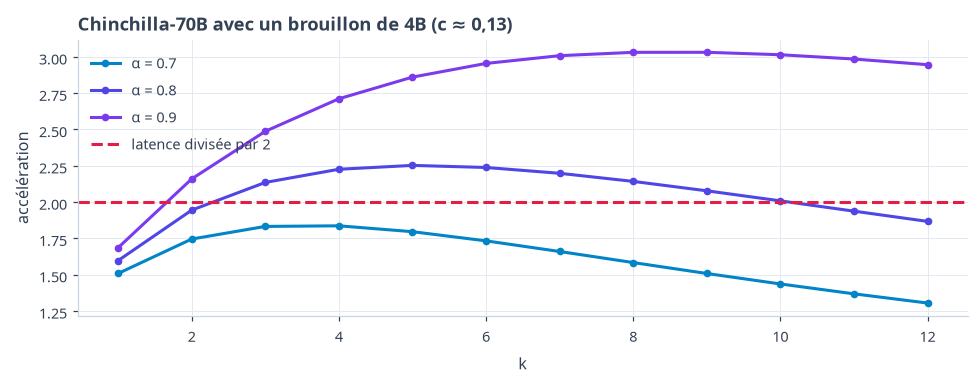

In [2]:
c_book = 1.8 / 14.1
ks = np.arange(1, 13)
S = inf.speculative_speedup(0.8, ks, c_book)
k_opt = inf.optimal_k(0.8, c_book)
print(f"c = {c_book:.3f} ; k optimal = {k_opt} ; accélération = {S[k_opt - 1]:.2f}"
      f" -> latence x {1 / S[k_opt - 1]:.2f}")
fig, ax = plt.subplots(figsize=(9, 3.6))
for a, col in [(0.7, SKY), (0.8, INDIGO), (0.9, VIOLET)]:
    ax.plot(ks, inf.speculative_speedup(a, ks, c_book), "o-", ms=4, color=col, label=f"α = {a}")
ax.axhline(2, color=ROSE, ls="--", label="latence divisée par 2")
ax.set_xlabel("k"); ax.set_ylabel("accélération"); ax.legend()
ax.set_title("Chinchilla-70B avec un brouillon de 4B (c ≈ 0,13)")
plt.tight_layout(); plt.show()

Avec $\alpha = 0{,}8$, l'optimum est vers $k = 4$ à 5 et l'accélération dépasse 2 : la
latence est bien plus que divisée par deux, conforme au livre. Avec $\alpha = 0{,}7$, on
reste sous 2 : le résultat est sensible au taux d'acceptation, donc au domaine.

**Vérification expérimentale** (question 3).

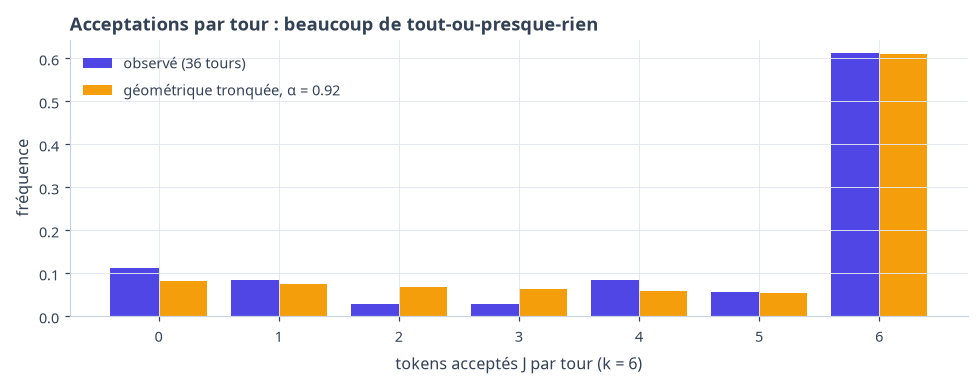

tokens par passe de la cible : mesuré 5.41, formule 5.53


In [3]:
tok_t, tgt = inf.retry_oom(llm.load, llm.MEDIUM)
tok_d, drf = inf.retry_oom(llm.load, llm.SMALL)
stop = inf.eos_ids(tok_t)
p = "Write a short Python class `Stack` with push, pop and peek methods, and a docstring for each."
ids_p = llm._chat_inputs(tok_t, p)["input_ids"][0].tolist()
r = inf.retry_oom(inf.assisted_generate, tgt, ids_p, inf.DraftModelProposer(drf), k=6, max_new_tokens=200, stop=stop)
J = np.array(r.rounds); P = np.array(r.proposed)
full = J[P == 6]  # tours complets (k = 6 propositions)
a_hat = inf.estimate_alpha(full, np.full_like(full, 6))
j_vals = np.arange(7)
theo = np.array([a_hat ** j * (1 - a_hat) for j in range(6)] + [a_hat ** 6])
obs = np.array([(full == j).mean() for j in j_vals])
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(j_vals - 0.2, obs, 0.4, color=INDIGO, label=f"observé ({len(full)} tours)")
ax.bar(j_vals + 0.2, theo, 0.4, color=AMBER, label=f"géométrique tronquée, α = {a_hat:.2f}")
ax.set_xlabel("tokens acceptés J par tour (k = 6)"); ax.set_ylabel("fréquence"); ax.legend()
ax.set_title("Acceptations par tour : beaucoup de tout-ou-presque-rien")
plt.tight_layout(); plt.show()
print(f"tokens par passe de la cible : mesuré {len(r.tokens) / r.forwards:.2f},"
      f" formule {float(inf.expected_tokens_per_round(a_hat, 6)):.2f}")

La forme générale (beaucoup de tours entièrement acceptés, un pic à $J = 0$) est bien
celle d'une géométrique tronquée, mais les écarts montrent que l'hypothèse
d'indépendance est approximative : les acceptations viennent **par séries** (passages
faciles, comme la syntaxe d'une classe Python, puis passages difficiles). La formule
donne néanmoins le bon ordre de grandeur pour le nombre de tokens par passe, qui est ce
qui compte pour l'accélération.

> **À retenir.** $\mathbb{E}[\text{tokens par tour}] = \frac{1-\alpha^{k+1}}{1-\alpha}$ ;
> l'accélération exige $\alpha$ élevé **et** $c$ faible, et le $k$ optimal croît avec
> $\alpha$. Mesurez $\alpha$ sur votre propre trafic : il dépend du domaine.

In [4]:
llm.free_gpu()
del tgt, drf